In [ ]:
## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
## 2. Load Dataset

In [ ]:
df=pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn 2.csv")

In [ ]:
## 3. Data Understanding

In [ ]:
df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df['TotalCharges'].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

In [ ]:
## 4. Data Cleaning

In [ ]:
df['TotalCharges'].str.strip().eq('').sum()

np.int64(11)

In [ ]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [ ]:
df[df['TotalCharges'].isnull()]['tenure']

,tenure
488,0
753,0
936,0
1082,0
1340,0
3331,0
3826,0
4380,0
5218,0
6670,0


In [ ]:
df=df.dropna(subset=['TotalCharges'])

In [ ]:
df.shape

(7032, 21)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
customerID,7032
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,72
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
df['Contract'].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

In [ ]:
df['PaymentMethod'].unique()

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df=df.drop('customerID', axis=1)

In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5163
Yes,1869


In [ ]:
df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.421502
Yes,26.578498


In [ ]:
## 5. Exploratory Data Analysis (EDA)

In [ ]:
### 5.1 Numerical Features

<Axes: xlabel='Churn', ylabel='count'>

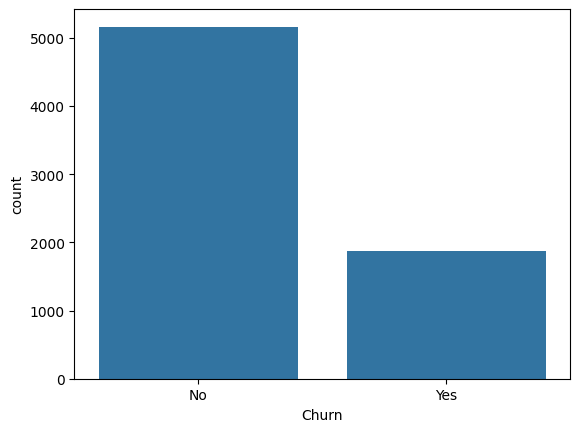

In [ ]:
sns.countplot(x='Churn', data=df)

In [ ]:
df['tenure'].describe()

,tenure
count,7032.000000
mean,32.421786
std,24.545260
min,1.000000
25%,9.000000
50%,29.000000
75%,55.000000
max,72.000000


In [ ]:
df[['MonthlyCharges','TotalCharges']].describe()

,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000
mean,64.798208,2283.300441
std,30.085974,2266.771362
min,18.250000,18.800000
25%,35.587500,401.450000
50%,70.350000,1397.475000
75%,89.862500,3794.737500
max,118.750000,8684.800000


In [ ]:
df.groupby('Churn')['tenure'].mean()

,tenure
Churn,
No,37.650010
Yes,17.979133


In [ ]:
df.groupby('Churn')['MonthlyCharges'].mean()

,MonthlyCharges
Churn,
No,61.307408
Yes,74.441332


In [ ]:
df.groupby('Churn')['TotalCharges'].mean()

,TotalCharges
Churn,
No,2555.344141
Yes,1531.796094


In [ ]:
df.groupby('Churn')['Contract'].value_counts()

Churn  Contract      
No     Month-to-month    2220
       Two year          1637
       One year          1306
Yes    Month-to-month    1655
       One year           166
       Two year            48
Name: count, dtype: int64

In [ ]:
df.groupby('Contract')['Churn'].value_counts(normalize=True)*100

Contract        Churn
Month-to-month  No       57.290323
                Yes      42.709677
One year        No       88.722826
                Yes      11.277174
Two year        No       97.151335
                Yes       2.848665
Name: proportion, dtype: float64

In [ ]:
df.groupby('InternetService')['Churn'].value_counts(normalize=True)*100

InternetService  Churn
DSL              No       81.001656
                 Yes      18.998344
Fiber optic      No       58.107235
                 Yes      41.892765
No               No       92.565789
                 Yes       7.434211
Name: proportion, dtype: float64

In [ ]:
df.groupby('PaymentMethod')['Churn'].value_counts(normalize=True)*100

PaymentMethod              Churn
Bank transfer (automatic)  No       83.268482
                           Yes      16.731518
Credit card (automatic)    No       84.746877
                           Yes      15.253123
Electronic check           No       54.714588
                           Yes      45.285412
Mailed check               No       80.798005
                           Yes      19.201995
Name: proportion, dtype: float64

In [ ]:
df.groupby('SeniorCitizen')['Churn'].value_counts(normalize=True)*100

SeniorCitizen  Churn
0              No       76.349745
               Yes      23.650255
1              No       58.318739
               Yes      41.681261
Name: proportion, dtype: float64

In [ ]:
### 5.2 Categorical Features

<Axes: xlabel='Contract', ylabel='count'>

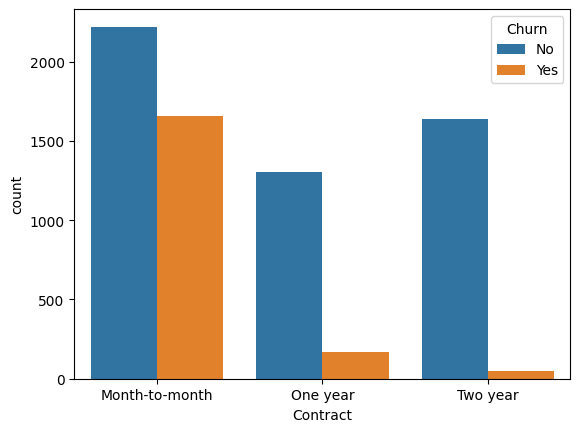

In [ ]:
sns.countplot(x='Contract',hue='Churn',data=df)

<Axes: xlabel='PaymentMethod', ylabel='count'>

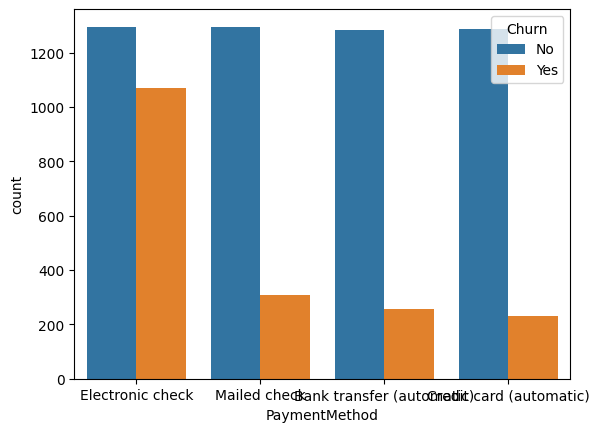

In [ ]:
sns.countplot(x='PaymentMethod',hue='Churn',data=df)

<Axes: xlabel='InternetService', ylabel='count'>

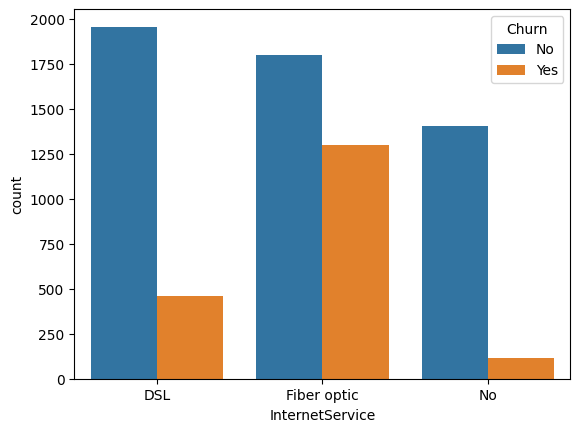

In [ ]:
sns.countplot(x='InternetService',hue='Churn',data=df)

<Axes: xlabel='SeniorCitizen', ylabel='count'>

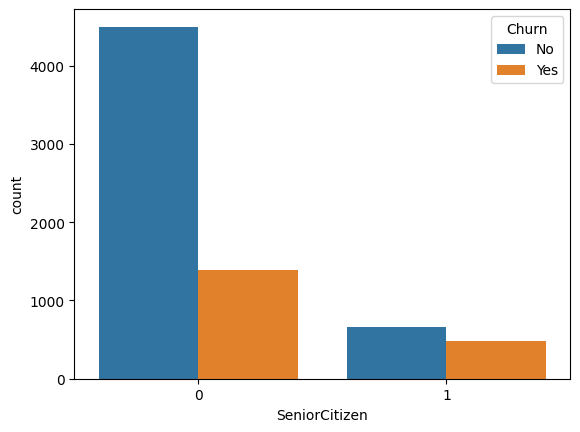

In [ ]:
sns.countplot(x='SeniorCitizen',hue='Churn',data=df)

<Axes: xlabel='gender', ylabel='count'>

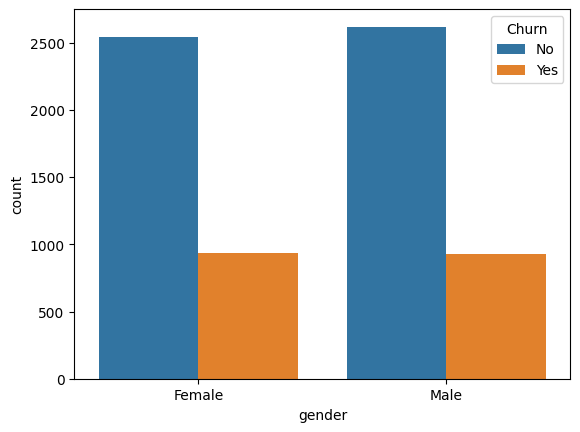

In [ ]:
sns.countplot(x='gender',hue='Churn',data=df)

<Axes: xlabel='Churn', ylabel='tenure'>

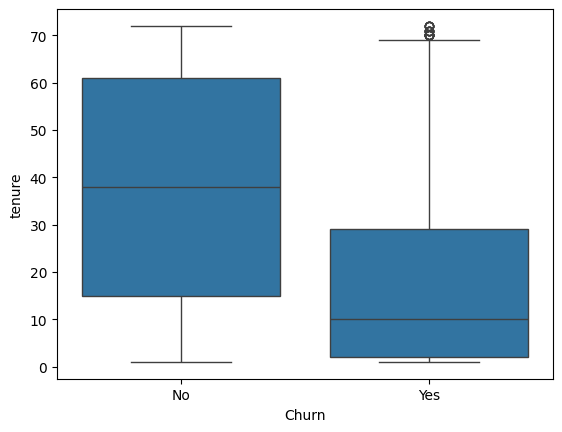

In [ ]:
sns.boxplot(x='Churn',y='tenure',data=df)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

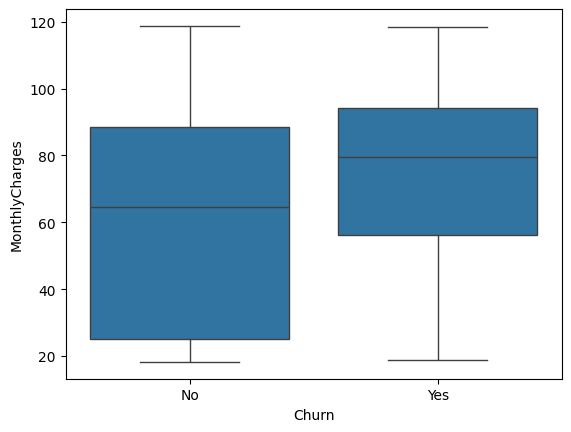

In [ ]:
sns.boxplot(x='Churn',y='MonthlyCharges',data=df)

In [ ]:
## Separate features and target
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'Yes': 1, 'No': 0})

In [ ]:
print(X.shape, y.shape)
print(y.value_counts())

(7032, 19) (7032,)
Churn
0    5163
1    1869
Name: count, dtype: int64


In [ ]:
## 6 Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
print(X_train.shape, X_test.shape)

(5625, 19) (1407, 19)


In [ ]:
## 7 Feature Enginerring

In [ ]:
X_train['tenure_group'] = pd.cut(X_train['tenure'], bins=[0, 12, 24, 48, 72],
                                  labels=['0-12', '12-24', '24-48', '48+'])

In [ ]:
X_train[['tenure', 'tenure_group']].head()

,tenure,tenure_group
1413,65,48+
7003,26,24-48
3355,68,48+
4494,3,0-12
3541,49,48+


In [ ]:
X_test['tenure_group'] = pd.cut(X_test['tenure'], bins=[0, 12, 24, 48, 72],
                                 labels=['0-12', '12-24', '24-48', '48+'])

In [ ]:
X_test[['tenure', 'tenure_group']].head()

,tenure,tenure_group
974,59,48+
619,7,0-12
4289,54,48+
3721,2,0-12
4533,71,48+


In [ ]:
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']
X_train['num_addons'] = (X_train[addon_cols] == 'Yes').sum(axis=1)
X_train[addon_cols + ['num_addons']].head()

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,num_addons
1413,Yes,Yes,Yes,Yes,No,No,4
7003,No,No,Yes,Yes,No,No,2
3355,No,Yes,Yes,Yes,No,No,3
4494,No,Yes,No,No,No,Yes,2
3541,Yes,No,No,No,Yes,No,2


In [ ]:
X_test['num_addons'] = (X_test[addon_cols] == 'Yes').sum(axis=1)
X_test[addon_cols + ['num_addons']].head()

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,num_addons
974,No,Yes,No,Yes,Yes,Yes,4
619,No,Yes,No,No,No,No,1
4289,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,0
3721,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,0
4533,No,Yes,Yes,No,Yes,Yes,4


In [ ]:
X_train['avg_monthly_spend'] = X_train['TotalCharges'] / X_train['tenure']
X_test['avg_monthly_spend'] = X_test['TotalCharges'] / X_test['tenure']

In [ ]:
X_train[['TotalCharges', 'tenure', 'avg_monthly_spend']].head()


,TotalCharges,tenure,avg_monthly_spend
1413,6078.75,65,93.519231
7003,1022.50,26,39.326923
3355,6297.65,68,92.612500
4494,235.05,3,78.350000
3541,2070.75,49,42.260204


In [ ]:
autopay = ['Bank transfer (automatic)', 'Credit card (automatic)']
X_train['auto_pay'] = X_train['PaymentMethod'].isin(autopay).astype(int)
X_test['auto_pay'] = X_test['PaymentMethod'].isin(autopay).astype(int)

In [ ]:
for col in ['tenure_group', 'num_addons', 'auto_pay']:
    print(pd.Series(y_train).groupby(X_train[col], observed=True).mean().round(3), '\n')

tenure_group
0-12     0.480
12-24    0.285
24-48    0.201
48+      0.098
Name: Churn, dtype: float64 

num_addons
0    0.214
1    0.457
2    0.353
3    0.276
4    0.225
5    0.126
6    0.059
Name: Churn, dtype: float64 

auto_pay
0    0.350
1    0.157
Name: Churn, dtype: float64 



In [ ]:
for X_ in [X_train, X_test]:
    X_['tenure_group'] = X_['tenure_group'].astype(str)

numerical_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()
print(len(numerical_features), len(categorical_features))

7 16


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numerical_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])

In [ ]:
## 8 Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

model_v2 = Pipeline([("preprocessor", preprocessor),
                     ("classifier", LogisticRegression(max_iter=1000))])
model_v2.fit(X_train, y_train)

proba = model_v2.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, model_v2.predict(X_test)))

ROC-AUC: 0.835
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



In [ ]:
new_feats = ['tenure_group', 'num_addons', 'avg_monthly_spend', 'auto_pay']
raw_cols = [c for c in X_train.columns if c not in new_feats]

raw_num = X_train[raw_cols].select_dtypes(include=['number']).columns.tolist()
raw_cat = X_train[raw_cols].select_dtypes(include=['object']).columns.tolist()

base_pre = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), raw_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), raw_cat)
])

churn_model = Pipeline([("preprocessor", base_pre),
                        ("classifier", LogisticRegression(max_iter=1000))])
churn_model.fit(X_train[raw_cols], y_train)

proba_base = churn_model.predict_proba(X_test[raw_cols])[:, 1]
print("Baseline ROC-AUC:", round(roc_auc_score(y_test, proba_base), 3))

Baseline ROC-AUC: 0.836


In [ ]:
## 9 Light GBM

In [ ]:
from lightgbm import LGBMClassifier

lgbm_v2 = Pipeline([("preprocessor", preprocessor),
                    ("classifier", LGBMClassifier(random_state=42, verbose=-1))])
lgbm_v2.fit(X_train, y_train)

proba_lgbm = lgbm_v2.predict_proba(X_test)[:, 1]
print("LightGBM ROC-AUC:", round(roc_auc_score(y_test, proba_lgbm), 3))

LightGBM ROC-AUC: 0.828


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
lgbm_base = Pipeline([("preprocessor", base_pre),
                      ("classifier", LGBMClassifier(random_state=42, verbose=-1))])
lgbm_base.fit(X_train[raw_cols], y_train)

proba_lgbm_base = lgbm_base.predict_proba(X_test[raw_cols])[:, 1]
print("LightGBM baseline ROC-AUC:", round(roc_auc_score(y_test, proba_lgbm_base), 3))

LightGBM baseline ROC-AUC: 0.826


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
!pip install shap -q

In [ ]:
import shap

prep = lgbm_v2.named_steps["preprocessor"]
X_test_tx = prep.transform(X_test)
if hasattr(X_test_tx, "toarray"):
    X_test_tx = X_test_tx.toarray()

feature_names = prep.get_feature_names_out()
X_test_tx = pd.DataFrame(X_test_tx, columns=feature_names)

print(X_test_tx.shape)
print(feature_names[:5])

(1407, 52)
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'num__num_addons']


In [ ]:
explainer = shap.TreeExplainer(lgbm_v2.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_tx)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

print(shap_values.shape)

(1407, 52)


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


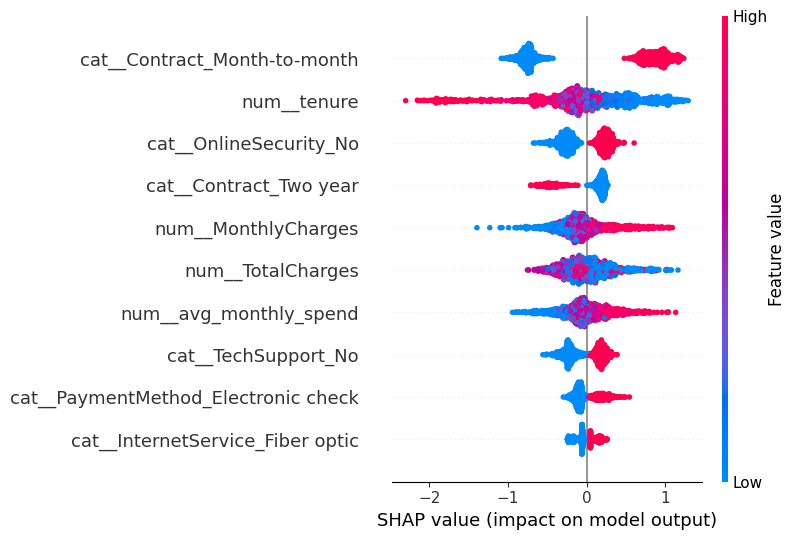

In [ ]:
shap.summary_plot(shap_values, X_test_tx, max_display=10)

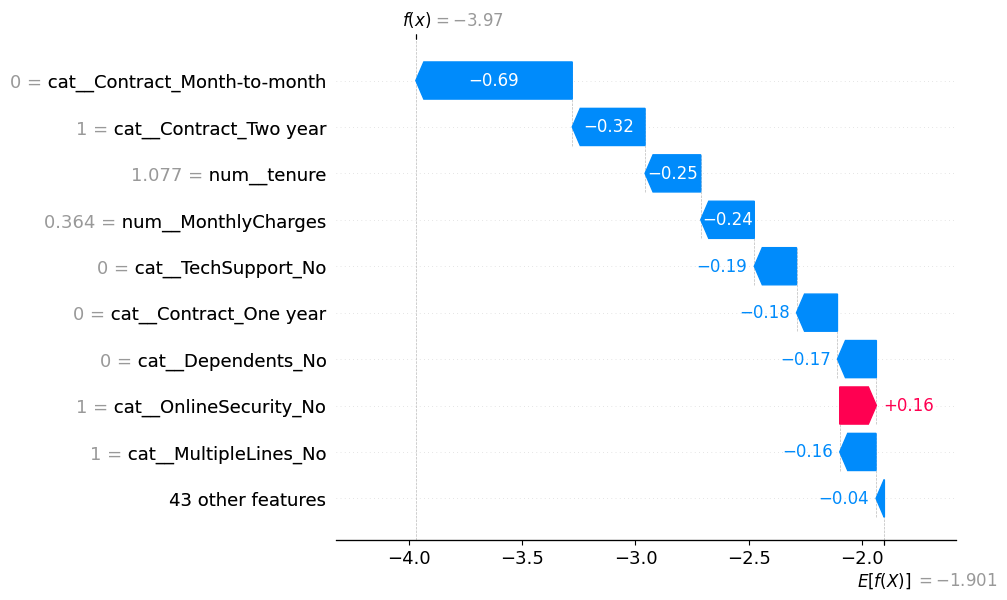

In [ ]:
i = 0
shap.waterfall_plot(shap.Explanation(
    values=shap_values[i],
    base_values=explainer.expected_value,
    data=X_test_tx.iloc[i].values,
    feature_names=X_test_tx.columns.tolist()
), max_display=10)

In [ ]:
!pip install lifelines -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


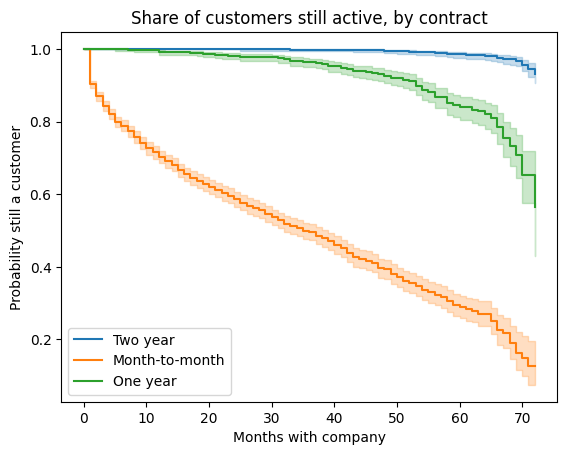

In [ ]:
## 10 Kaplan-Meier curves by contract type

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()
ax = plt.subplot(111)

for contract in X_train['Contract'].unique():
    mask = X_train['Contract'] == contract
    kmf.fit(X_train.loc[mask, 'tenure'], event_observed=y_train[mask], label=contract)
    kmf.plot_survival_function(ax=ax)

plt.title('Share of customers still active, by contract')
plt.xlabel('Months with company')
plt.ylabel('Probability still a customer')
plt.show()

In [ ]:
## 11 Cox model

from lifelines import CoxPHFitter

cox_df = X_train[['tenure', 'MonthlyCharges', 'num_addons', 'auto_pay', 'SeniorCitizen']].copy()
cox_df['Contract_One_year'] = (X_train['Contract'] == 'One year').astype(int)
cox_df['Contract_Two_year'] = (X_train['Contract'] == 'Two year').astype(int)
cox_df['Churn'] = y_train.values

cph = CoxPHFitter()
cph.fit(cox_df, duration_col='tenure', event_col='Churn')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 5625 total observations, 4130 right-censored observations>
             duration col = 'tenure'
                event col = 'Churn'
      baseline estimation = breslow
   number of observations = 5625
number of events observed = 1495
   partial log-likelihood = -10907.55
         time fit was run = 2026-10-25 12:52:58 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                          
MonthlyCharges     0.02      1.02      0.00            0.01            0.02                1.01                1.02
num_addons        -0.40      0.67      0.03           -0.45           -0.34                0.64                0.71
auto_pay          -0.71      0.49      0.06           -0.83           -0.59                0.44                0.55
SeniorCitizen     -0.05      0.95      0.06           -0.17            0.07                0.84                1.07
Contract_One_year -1.87      0.15      0.10           -2.07           -1.68                0.13                0.19
Contract_Two_year -3.63      0.03      0.18           -3.98           -3.29                0.02                0.04

                   cmp to      z      p  -log2(p)
covariate                                        
MonthlyCharges       0.00  10.35 <0.005     80.99
num_addons           0.00 -15.30 <0.005    173.13
auto_pay             0.00 -11.71 <0.005    102.75
SeniorCitizen        0.00  -0.87   0.38      1.38
Contract_One_year    0.00 -18.91 <0.005    262.48
Contract_Two_year    0.00 -20.57 <0.005    309.80
---
Concordance = 0.85
Partial AIC = 21827.10
log-likelihood ratio test = 2545.82 on 6 df
-log2(p) of ll-ratio test = inf

In [ ]:
hill = pd.read_csv("/content/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")
hill.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [ ]:
hill['treatment'] = (hill['segment'] != 'No E-Mail').astype(int)
hill['treatment'].value_counts()

,count
treatment,
1,42694
0,21306


In [ ]:
hill.shape

(64000, 13)

In [ ]:
hill.groupby('treatment')['conversion'].mean()

,conversion
treatment,
0,0.005726
1,0.010681


In [ ]:
from sklearn.model_selection import train_test_split

features = ['recency', 'history', 'mens', 'womens', 'newbie',
            'history_segment', 'zip_code', 'channel']
X_h = pd.get_dummies(hill[features], columns=['history_segment', 'zip_code', 'channel'],
                     drop_first=True, dtype=int)

X_tr, X_te, t_tr, t_te, y_tr, y_te = train_test_split(
    X_h, hill['treatment'], hill['conversion'],
    test_size=0.2, random_state=42, stratify=hill['treatment']
)

print(X_tr.shape, X_te.shape)

(51200, 15) (12800, 15)


In [ ]:
!pip install causalml -q
from causalml.inference.meta import BaseTClassifier
from sklearn.linear_model import LogisticRegression

t_model = BaseTClassifier(learner=LogisticRegression(max_iter=1000))
t_model.fit(X=X_tr.values, treatment=t_tr.values, y=y_tr.values)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


BaseTClassifier(learner=LogisticRegression(max_iter=1000))

In [ ]:
uplift = t_model.predict(X=X_te.values)
print(uplift.shape)
print(uplift[:5].round(4))

(12800, 1)
[[0.0088]
 [0.0036]
 [0.0039]
 [0.003 ]
 [0.0044]]


In [ ]:
test_df = pd.DataFrame({'uplift': uplift.ravel(),
                        't': t_te.values,
                        'y': y_te.values})
test_df['group'] = pd.qcut(test_df['uplift'], 5,
                           labels=['Bottom 20%', '2nd', '3rd', '4th', 'Top 20%'])

def real_uplift(g):
    return g.loc[g['t'] == 1, 'y'].mean() - g.loc[g['t'] == 0, 'y'].mean()

print(test_df.groupby('group', observed=True).apply(real_uplift).round(4))

group
Bottom 20%    0.0018
2nd           0.0022
3rd           0.0044
4th           0.0038
Top 20%       0.0134
dtype: float64


/tmp/ipykernel_1931/1048735162.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(test_df.groupby('group', observed=True).apply(real_uplift).round(4))


In [ ]:
covariates = cox_df.drop(columns=['tenure', 'Churn'])
expected_life = cph.predict_expectation(covariates)
print(expected_life.describe().round(1))

count    5625.0
mean       49.0
std        18.7
min        14.7
25%        31.3
50%        49.1
75%        68.8
max        70.8
dtype: float64


In [ ]:
clv = X_train['MonthlyCharges'] * expected_life.values
print(clv.describe().round(0))

count    5625.0
mean     3152.0
std      2057.0
min       596.0
25%      1435.0
50%      2409.0
75%      4538.0
max      8324.0
Name: MonthlyCharges, dtype: float64


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

seg_cols = X_train[['tenure', 'MonthlyCharges']].copy()
seg_scaled = StandardScaler().fit_transform(seg_cols)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
seg = kmeans.fit_predict(seg_scaled)

In [ ]:
profile = seg_cols.assign(clv=clv.values, segment=seg, churned=y_train.values)
print(profile.groupby('segment').mean().round(1))

         tenure  MonthlyCharges     clv  churned
segment                                         
0          15.0            81.4  2873.3      0.5
1          54.3            34.0  2162.1      0.0
2          58.9            93.1  5614.5      0.2
3          10.8            32.7  1360.9      0.2


In [ ]:
summary = profile.groupby('segment').agg(
    customers=('clv', 'size'),
    avg_clv=('clv', 'mean'),
    total_clv=('clv', 'sum'),
)
summary['share_of_total'] = (summary['total_clv'] / summary['total_clv'].sum() * 100).round(1)
print(summary.round(0))

         customers  avg_clv  total_clv  share_of_total
segment                                               
0             1754   2873.0  5039799.0            28.0
1              905   2162.0  1956698.0            11.0
2             1575   5614.0  8842805.0            50.0
3             1391   1361.0  1892959.0            11.0


In [ ]:
test_cox = X_test[['MonthlyCharges', 'num_addons', 'auto_pay', 'SeniorCitizen']].copy()
test_cox['Contract_One_year'] = (X_test['Contract'] == 'One year').astype(int)
test_cox['Contract_Two_year'] = (X_test['Contract'] == 'Two year').astype(int)

exp_months = cph.predict_expectation(test_cox).values

roi_df = pd.DataFrame({
    'monthly_bill': X_test['MonthlyCharges'].values,
    'expected_months': exp_months,
    'clv': X_test['MonthlyCharges'].values * exp_months,
    'churn_prob': lgbm_v2.predict_proba(X_test)[:, 1],
})
roi_df.to_csv('roi_customers.csv', index=False)
print(roi_df.describe().round(2))

       monthly_bill  expected_months      clv  churn_prob
count       1407.00          1407.00  1407.00     1407.00
mean          63.99            48.26  3054.64        0.27
std           29.99            18.98  2032.45        0.27
min           18.25            14.67   597.75        0.00
25%           34.55            31.16  1381.72        0.03
50%           69.90            47.27  2314.32        0.16
75%           89.40            68.50  4440.46        0.46
max          118.75            70.82  8381.79        0.96


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
## 12 the Streamlit app

In [ ]:
%%writefile app.py
import pandas as pd
import streamlit as st

st.title("Churn Discount ROI Simulator")

df = pd.read_csv("roi_customers.csv")

discount = st.slider("Discount on customer's bill (%)", 0, 50, 10)
reduction = st.slider("Share of churn risk the discount removes (%)", 0, 100, 30)
threshold = st.slider("Offer only to customers with churn chance above (%)", 0, 100, 30)

targets = df[df['churn_prob'] >= threshold / 100]

# Savings: churn risk removed, valued at each customer's CLV
savings = (targets['churn_prob'] * reduction / 100 * targets['clv']).sum()
# Cost: the discount, applied to the value of the customer's remaining bills
cost = (discount / 100 * targets['clv']).sum()
net = savings - cost

col1, col2, col3 = st.columns(3)
col1.metric("Customers targeted", f"{len(targets):,}")
col2.metric("Expected savings", f"${savings:,.0f}")
col3.metric("Discount cost", f"${cost:,.0f}")

st.metric("Net gain", f"${net:,.0f}")
if net > 0:
    st.success("This offer pays for itself under these assumptions.")
else:
    st.error("This offer costs more than it saves under these assumptions.")

Overwriting app.py
